In [1]:
import numpy as np
import matplotlib.pyplot as plt
import re

import ase.io as aio


In [4]:
def get_atom_numers(w_uc,  N_O_mag_uc, N_Fe_mag_uc, N_OS_uc, N_FeS_uc, N_FeS2_uc ):
    #calculate number of atom in the whole config, of every species and per surface.
    #determine the size factor "f": f_small=3x3=9; f_big=6x6=36;   f_full_coverage=4x4=16: 
    
    print(f"Water/uc/Surface = {w_uc}")
    if w_uc in (1,2,3,4):
        f=9
    elif w_uc in (5,6,7,8):
        f=36
    elif w_uc==68:
        f=16
    print(f"size_factor = {f}")
    
    
    if w_uc in (1,2,3,4):
        L_x=25.08508
        L_y=25.08508
        L_z=28.85502 
    elif w_uc in (5,6,7,8):
        L_x =50.17016 
        L_y =50.17016 
        L_z =34.62602 
    elif w_uc==68:
        L_x=33.584 
        L_y=33.584 
        L_z=71.47838

    diag_lenght=np.sqrt(L_x**2+L_y**2) #simulation box xy diagonal lenght to add boundaries 
    print("diag_lenght=" , diag_lenght)
    
    
    
    
    
    
    #species
    N_water=w_uc*f*2         #*2 surfaces
    N_H=N_water*2             
    N_O_mag=N_O_mag_uc*f
    N_O=N_O_mag+N_water
    N_Fe=N_Fe_mag_uc*f
    N_atom=N_H+N_O+N_Fe

    #surface
    N_OS=N_OS_uc*f
    N_FeS=N_FeS_uc*f
    N_FeS2= N_FeS2_uc*f

    

    print(f"N_water = {N_water}")
    print(f"N_H = {N_H}")
    print(f"N_O = {N_O}")
    print(f"N_Fe = {N_Fe}")
    print(f"N_atom = {N_atom}")
    print(f"N_O surface = {N_OS}")
    print(f"N_Fe surface = {N_FeS}")
    print(f"N_Fe surface2 = {N_FeS2}")
    return(f, diag_lenght,  N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2 )

In [5]:
def parser(t_slice,  N_water, N_O, N_OS, N_Fe, N_FeS, N_FeS2):
    
    H_u=[]
    H_d=[]
    O_u=[]
    O_d=[]
    OS_u=[]
    OS_d=[]
    FeS_u=[]
    FeS_d=[]
    FeS2_u=[]
    FeS2_d=[]
    
    
    positions=t_slice.get_positions(wrap=True)
   
    #indices species 
    H_indices = np.where(t_slice.get_atomic_numbers()==1)[0]
    O_indices = np.where(t_slice.get_atomic_numbers()==2 )[0]
    Fe_indices = np.where(t_slice.get_atomic_numbers()==3 )[0]
 
    
    #H
    H_u=positions[H_indices[:N_water]]
    H_d=positions[H_indices[N_water:]]
    #O 
    #water_u
    O_u= positions[O_indices[:int(N_water/2)]] 
    OS_u= positions[O_indices[int(N_water/2):int(N_water/2)+N_OS]] 
    OS_d=positions[O_indices[ N_O -int(N_water/2) -N_OS:  N_O -int(N_water/2)   ]] 
    O_d=positions[O_indices[  N_O -int(N_water/2) :  ]] 
   
    #Fe
    FeS_u= positions[Fe_indices[:N_FeS]]    #surface up
    FeS2_u= positions[Fe_indices[N_FeS: N_FeS+ N_FeS2 ]]     #2 surface up
    FeS2_d= positions[Fe_indices[ N_Fe - N_FeS- N_FeS2 : N_Fe - N_FeS ] ]   #2 surface down
    FeS_d= positions[Fe_indices[N_Fe - N_FeS :]]
  
    
    #checks
    if len(H_u) != N_water:
      print(f"H Err:  {len(H_u) - N_water} atom" )
    if len(H_d) != N_water:
      print(f"H Err:  {len(H_d) - N_water} atom" )
    if len(O_u) != N_water/2:
      print(f"O Err: {len(O_u) - N_water/2} atom" ) 
    if len(O_d) != N_water/2:
      print(f"O Err: {len(O_d) - N_water/2} atom" ) 
    if len(OS_u) != N_OS:
      print(f"OS_u Err: {len(OS_u) - N_OS} atom" )
    if len(OS_d) != N_OS:
      print(f"OS_d Err: {len(OS_d) - N_OS} atom" )
    if len(FeS_u) != N_FeS:
      print(f"FeS_u Err: {len(FeS_u) - N_FeS} atom" )
    if len(FeS_d) != N_FeS:
      print(f"FeS_d Err: {len(FeS_d) - N_FeS} atom" )
    if len(FeS2_u) != N_FeS2:
      print(f"FeS2_u Err: {len(FeS2_u) - N_FeS2} atom" )
    if len(FeS2_d) != N_FeS2:
      print(f"FeS2_d Err: {len(FeS2_d) - N_FeS2} atom" )
     
    
   
    return H_u, H_d, O_u, O_d, OS_u, OS_d, FeS_u, FeS_d, FeS2_u, FeS2_d

In [7]:
#give #H or #O of water, z of the surface up and down , and cut distance
# 2) (surface u) shifting z to zero, (surface d) shifting  z to zero  and inverting
def surface_up_down_translate(A_u, A_d, z_u, z_d,  max_distance):
    
    tmp_u=[]
    tmp_d=[]
  
    for atom in A_u:
        #if  z_u  <atom[2]<  z_u + max_distance  :
            tmp_u.append( [atom[0], atom[1],    atom[2]-z_u ])
            
    for atom in A_d:    
       #if z_d -  max_distance < atom[2]<  z_d:
            tmp_d.append([atom[0], atom[1], -atom[2]+z_d])
  


    return tmp_u, tmp_d

def up_down_z_all_t_extractor(H_u, H_d ):
    zH_ud=[]
    for atom in H_u:
            zH_ud.append(atom[2])
    for atom in H_d:
            zH_ud.append(atom[2])

   # print(len(zH_ud))
    return zH_ud

#determine exactly the surfaces positions with average of z of all atom in the surface: give atoms in a layer
def get_layer_z(A):
    z=A[:,2]
    return np.mean(z), max(z), min(z)

In [8]:
#oct and tet analysis based on oxygens surface layer: OS_u or OS_d as input, box xy diagonal, and  cluster parm epsilon =1

#output diagonal O raws displacment to separate (Fe) oct and tet zones
def get_diagonal_O_raws(OS_u, control, diag_lenght,  epsilon):
    diagonal_projection=[]

    
    for atom in OS_u:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
        #print(theta)
        if control == 'u':
            diagonal_projection.append(r*np.cos(theta - (np.pi/4)  )   )
        elif control == 'd':
            diagonal_projection.append(r*np.sin(theta - (np.pi/4)  )   )
        else:
            print("control must be 'u' or 'd'")
            return

    #clusterization of diagonal projection of O position in raws
    displacement=[]
    
    displacement.append([diagonal_projection[0]])

    for i, proj in enumerate(diagonal_projection[1:]):
        copy=displacement
     
        for j in range(len(copy)):
            #print(j)
            if np.abs(proj-displacement[j][0])<epsilon:
                displacement[j].append(proj)
                #print("existing")
                break
            elif j==len(copy)-1:      #last round and no match found create new entry
                #print("new")
                displacement.append([proj])


    #average over the O diagonal raws
    mean_displacement=[]   
    for i in displacement:
        mean_displacement.append(np.mean(i))
    mean_displacement=list(np.sort(mean_displacement))
   
    if control == 'u':
        mean_displacement.insert(0,0)
        mean_displacement.append(diag_lenght)
    else:
        mean_displacement.insert(0,-diag_lenght/2)
        mean_displacement.append(diag_lenght/2)
    #print(mean_displacement)
    return list(mean_displacement)


#oct/tet regions atomic separation; inside O raws = oct, outside = tet: 
def tet_oct_split(O_u, diag_raw , control ):
      
    O_oct_u=[]
    O_tet_u=[]
   
    for atom in O_u:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
    
        if control == 'u':
            diagonal_projection=(r*np.cos(theta - (np.pi/4)  ))     #up cos raws   \\\\\           
        elif control == 'd':
            diagonal_projection=(r*np.sin(theta - (np.pi/4)  ))     #down sin raws  /////   
            
        else:  
            print("control must be 'u' or 'd'")
            return   
        
        if diagonal_projection <diag_raw[0] or diagonal_projection > diag_raw[-1]:  #inbound check
                print("OUT of bounds: diag =" , diagonal_projection, "cartesian =", atom)
                
        if (diag_raw[2]-diag_raw[1])<(diag_raw[3]-diag_raw[2]):           #check if the first raw (the zero is the border)is oct or tet (if T == oct if F ==tet )
            # first raw is oct
            #if diagonal projection in (diag_raw[2n],diag_raw[2n+1])   then tet region  even!
            #if diagonal projection in (diag_raw[2n+1],diag_raw[2n+2]) then oct region odd!
            for n in range(len(diag_raw)-1):  
                if diag_raw[n] <= diagonal_projection <= diag_raw[n+1]: 
                    if n % 2 ==0:
                        O_tet_u.append([atom[0], atom[1], atom[2]]) #n even ==> outside O raws == tet region
                    else:
                        O_oct_u.append([atom[0], atom[1], atom[2]]) #n odd ==> inside O raws == oct region
                    break
        else:
            #first raw is tet
            for n in range(len(diag_raw)-1):  
                if diag_raw[n] <= diagonal_projection <= diag_raw[n+1]: 
                    if n % 2 ==0:
                        O_oct_u.append([atom[0], atom[1], atom[2]]) #n even ==> inside O raws == oct region
                    else:
                        O_tet_u.append([atom[0], atom[1], atom[2]]) #n odd ==> outside O raws == tet region
                    break
        
    if len(O_oct_u)+len(O_tet_u) != len(O_u):
        print("MISSING ATOM: ",len(O_u)-  (len(O_oct_u)+len(O_tet_u))) 
    return O_oct_u,  O_tet_u

In [14]:
#magnetite u.c. data
N_O_mag_uc=64
N_Fe_mag_uc=44
N_OS_uc=8    # number oxygen in first outer layer/uc
N_FeS_uc=4   # number of iron in first outer layer/uc
N_FeS2_uc=3  # number of iron  second/outer layer/uc



#IMPORTANT: trj must be ordered by z and clustered by atom
trj="./water_1_uc/run_2/cut.trj_4500"      #path to trj
w_uc=1             #water per uc per surface: between 1 and 8 or 68==full_coverage (consistent with trj loaded)


#dize factor, diagonal, tot number of H, O, Fe, number of O in the magnetite surface and Fe in the 2 outermost layers 
f,diag_lenght, N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2 = get_atom_numers(w_uc, N_O_mag_uc, N_Fe_mag_uc, N_OS_uc, N_FeS_uc, N_FeS2_uc)





Water/uc/Surface = 1
size_factor = 9
diag_lenght= 35.47566034921408
N_water = 18
N_H = 36
N_O = 594
N_Fe = 396
N_atom = 1026
N_O surface = 72
N_Fe surface = 36
N_Fe surface2 = 27


In [15]:

control_u='u'
control_d='d'

max_distance=5 #cut distance from each surface: <26 

#hinstograms init
n_bin=500
dx=1/n_bin
bins = np.linspace(0, max_distance, n_bin) 
bins_centers=(bins[1:]+bins[:-1])/2


H_ud_hist=[0]*(n_bin-1)
O_ud_hist=[0]*(n_bin-1)
N_H_ud=0       #Total Number of H up and down in every t
N_O_ud=0
H_tet_ud_hist=[0]*(n_bin-1)
H_oct_ud_hist=[0]*(n_bin-1)
O_tet_ud_hist=[0]*(n_bin-1)
O_oct_ud_hist=[0]*(n_bin-1)
N_H_oct_ud=0
N_H_tet_ud=0
N_O_oct_ud=0
N_O_tet_ud=0
#time
t=0
for t_slice in aio.iread(trj,format='lammps-dump-text'):
     t+=1
     H_u, H_d, O_u, O_d, OS_u, OS_d, FeS_u, FeS_d, FeS2_u, FeS2_d = parser(t_slice,  N_water, N_O, N_OS, N_Fe, N_FeS, N_FeS2 )
    
     #get surfaces infos (sporadic)
     S_u, S_u_min, S_u_max =get_layer_z(np.concatenate((OS_u,FeS_u),axis=0 ))
     S2_u, S2_u_min, S2_u_max =get_layer_z(FeS2_u)
     
     S_d, S_d_min, S_d_max =get_layer_z(np.concatenate((OS_d,FeS_d),axis=0 ))     
     S2_d, S2_d_min, S2_d_max =get_layer_z(FeS2_d)
     
     #update surdaces z boundary  (sporadic not really working)

     #z_interval_u=[S_u_max+eps,  (S_u_min+ S2_u_max)/2, S2_u_min-eps  ]
     #z_interval_d=[S_d_min-eps,  (S_d_max+ S2_d_min)/2, S2_d_max+eps  ] 
       
     #get O raws info (sporadic)
     diag_raw_u=get_diagonal_O_raws(OS_u, control_u, diag_lenght, 1 ) #give OS_u or OS_d, control u or d accordingly, diag_lenght and cluster param
     diag_raw_d=get_diagonal_O_raws(OS_d, control_d, diag_lenght, 1 ) #give OS_u or OS_d, control u or d accordingly, diag_lenght and cluster param
     
    
     
     # translate to 0 the surfaces (and invert the d)
     H_u, H_d=surface_up_down_translate(H_u, H_d, S_u, S_d,  max_distance)
     O_u, O_d=surface_up_down_translate(O_u, O_d, S_u, S_d,  max_distance)
     
     #UP DOWN DENSITY PLOT
     #extract z and unify
     zH_ud=up_down_z_all_t_extractor(H_u, H_d )                 
     zO_ud=up_down_z_all_t_extractor(O_u, O_d )
     
     #make instograms NOT normalized, NOT density
     H_ud_hist+=np.histogram(zH_ud, bins=bins)[0]
     N_H_ud+=len(zH_ud)    
     O_ud_hist+=np.histogram(zO_ud, bins=bins)[0]
     N_O_ud+=len(zO_ud)
     
     #OCT/TET UP/DOWN DENSITY PLOT
     #split oct/tet
     O_oct_u, O_tet_u=tet_oct_split(O_u, diag_raw_u , control_u )     
     O_oct_d, O_tet_d=tet_oct_split(O_d, diag_raw_d , control_d )
     H_oct_u, H_tet_u=tet_oct_split(H_u, diag_raw_u , control_u )
     H_oct_d, H_tet_d=tet_oct_split(H_d, diag_raw_d , control_d )
     #extract z and unify
     zH_tet_ud= up_down_z_all_t_extractor(H_tet_u, H_tet_d)           
     zH_oct_ud= up_down_z_all_t_extractor(H_oct_u, H_oct_d)
     zO_tet_ud= up_down_z_all_t_extractor(O_tet_u, O_tet_d)
     zO_oct_ud= up_down_z_all_t_extractor(O_oct_u, O_oct_d)
     
     #make instograms NOT normalized, NOT density
     H_tet_ud_hist+=np.histogram(zH_tet_ud, bins=bins)[0]
     N_H_tet_ud+=len(zH_tet_ud)

     H_oct_ud_hist+=np.histogram(zH_oct_ud, bins=bins)[0]
     N_H_oct_ud+=len(zH_oct_ud)

     O_tet_ud_hist+=np.histogram(zO_tet_ud, bins=bins)[0]
     N_O_tet_ud+=len(zO_tet_ud) 

     O_oct_ud_hist+=np.histogram(zO_oct_ud, bins=bins)[0]
     N_O_oct_ud+=len(zO_oct_ud)   
     #print(t)
     

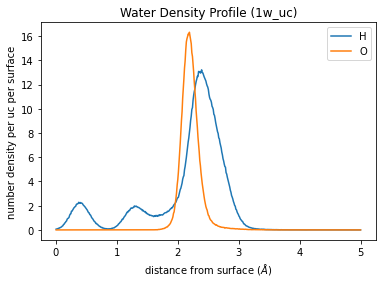

In [144]:


plt.plot(bins_centers,H_ud_hist/(t*dx*2*f), label='H')    #/(N_H_ud*t*dx) for normalization
plt.plot(bins_centers,O_ud_hist/(t*dx*2*f),label='O')
plt.legend()
plt.xlabel('distance from surface ($\\AA$)')
plt.ylabel('number density per uc per surface')
plt.title(f"Water Density Profile ({w_uc} w_uc)")
plt.savefig(f"W_density_profile_{w_uc}w_uc.png", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)
plt.show()

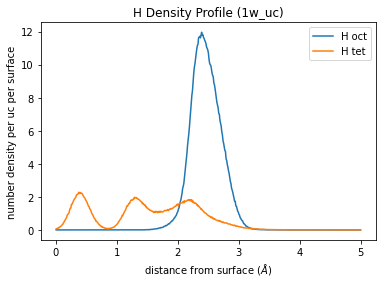

In [145]:
plt.plot(bins_centers,H_oct_ud_hist/(t*dx*2*f), label='H oct') #/(N_H_oct_ud*t*dx) for normalization
plt.plot(bins_centers,H_tet_ud_hist/(t*dx*2*f),label='H tet')
plt.legend()
plt.xlabel('distance from surface ($\\AA$)')
plt.ylabel('number density per uc per surface')
plt.title("H Density Profile (4w_uc)")
plt.savefig("H_density_profile_4w_uc.png", bbox_inches="tight", facecolor="white", transparent=True,  dpi=200)
plt.show()

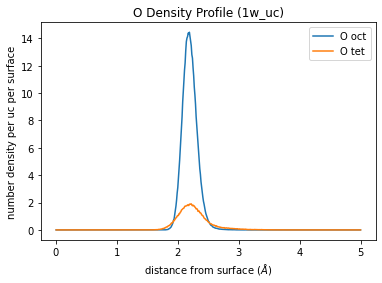

In [146]:
plt.plot(bins_centers,O_oct_ud_hist/(t*dx*2*f), label='O oct')  #/(N_O_oct_ud*t*dx) for normalization
plt.plot(bins_centers,O_tet_ud_hist/(t*dx*2*f),label='O tet')
plt.legend()
plt.xlabel('distance from surface ($\\AA$)')
plt.ylabel('number density per uc per surface')
plt.title("O Density Profile (4w_uc)")
plt.savefig("O_density_profile_4w_uc.png", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)
plt.show()